# Filbin 2018 — 05 · EMT-TF Expression (unconditional)
Score EMT / mesenchymal transcription factors on this dataset, gated on **detectable expression**.
The canonical Snail/Zeb/Twist panel is largely undetected in this SmartSeq2 glioma; we widen to
mesenchymal families (FOXC, PRRX) and pick the most **arm-specific detected TF per glial arm**.
VIM is a marker, not a TF, and is excluded. Categorical thresholded-overlay style (reference).

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
sc.settings.verbosity = 1; SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)

### Select arm-specific EMT-TFs — detection-gated, data-driven
Candidate mesenchymal TFs across families. Keep those detected in >=15% of cells, then for each
glial arm (from `signatures.h5ad`, non-cycling) take the TF with the strongest arm bias.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
sig = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obs['glial_arm'] = sig.obs['glial_arm'].reindex(adata.obs_names)
adata.obsm['X_umap'] = sig.obsm['X_umap']  # consistent orientation
adata.obs['celltype'] = sig.obs['celltype'].reindex(adata.obs_names)
cands = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in cands if g in adata.var_names]
X = adata[:, present].X.toarray(); det = (X>0).mean(0)
detected = [g for g,d in zip(present, det) if d >= 0.15]
print('detected EMT-TFs (>=15%):', {g: round(float(det[present.index(g)]),2) for g in detected})
nc = ~adata.obs['celltype'].isin(['Cycling-OPC'])
ac = (adata.obs.glial_arm=='AC-arm').values & nc.values
oc = (adata.obs.glial_arm=='OC-arm').values & nc.values
bias = {}
for g in detected:
    j = present.index(g); a, o = X[ac,j].mean(), X[oc,j].mean()
    bias[g] = (a, o)
AC_TF = max(detected, key=lambda g: bias[g][0]-bias[g][1])
OC_TF = max(detected, key=lambda g: bias[g][1]-bias[g][0])
print(f'AC-arm TF = {AC_TF} (AC {bias[AC_TF][0]:.2f} vs OC {bias[AC_TF][1]:.2f})')
print(f'OC-arm TF = {OC_TF} (OC {bias[OC_TF][1]:.2f} vs AC {bias[OC_TF][0]:.2f})')

detected EMT-TFs (>=15%): {'ZEB1': 0.79, 'ZEB2': 0.77, 'PRRX1': 0.57}
AC-arm TF = PRRX1 (AC 2.63 vs OC 1.63)
OC-arm TF = ZEB2 (OC 3.51 vs AC 2.41)


### Deliverable — `expression.pdf` (categorical thresholded overlay on grey manifold)

saved expression.pdf | EMT-TFs: PRRX1 (AC), ZEB2 (OC)


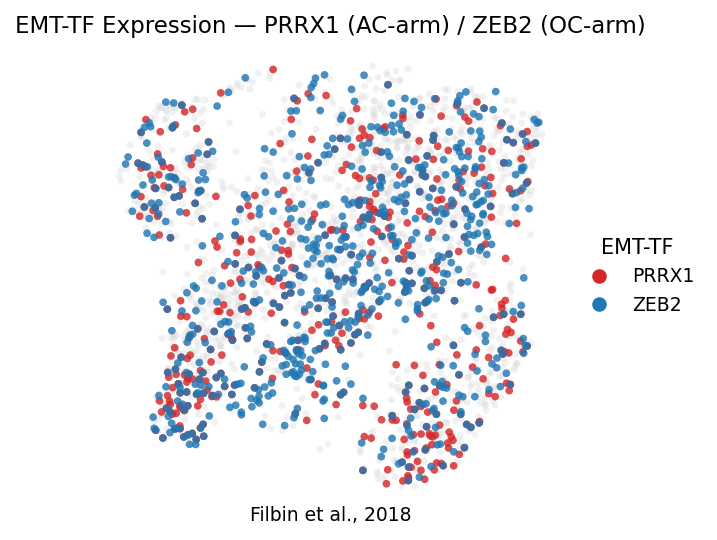

In [4]:
# thresholds set per-TF so overlay is not outlier-washed (75th pct of detected expression)
def thr(gene):
    v = adata[:, gene].X.toarray().ravel(); v = v[v>0]
    return float(np.percentile(v, 60)) if v.size else 0.0
g_plt = {AC_TF: ('tab:red', thr(AC_TF)), OC_TF: ('tab:blue', thr(OC_TF))}
fig, ax = plt.subplots(figsize=(4, 4))
sc.pl.umap(adata, size=45, alpha=.3, na_color='lightgrey', frameon=False, show=False, ax=ax)
handles = []
for var, (c, th) in g_plt.items():
    sub = adata[adata[:, var].X.toarray().ravel() > th]
    sc.pl.umap(sub, na_color=c, size=55, alpha=.8, frameon=False, show=False, ax=ax)
    handles.append(plt.Line2D([0],[0], marker='o', color='w', markerfacecolor=c, markersize=8, label=var))
ax.legend(handles=handles, frameon=False, loc='center left', bbox_to_anchor=(1.0,.5), fontsize=9, title='EMT-TF', title_fontsize=10)
ax.set_title(f'EMT-TF Expression — {AC_TF} (AC-arm) / {OC_TF} (OC-arm)', size=11)
ax.text(.5, -.03, 'Filbin et al., 2018', ha='center', transform=ax.transAxes, size=9)
fig.savefig(os.path.join(pth_fig, 'expression.pdf'), bbox_inches='tight'); plt.show()
print('saved expression.pdf | EMT-TFs:', AC_TF, '(AC),', OC_TF, '(OC)')